# 03 — Signal Processing of MEMS Sensor Data

## Objective

The purpose of this notebook is to analyse the simulated MEMS sensor response in the time and frequency domains.

The previous notebooks established the deterministic dynamical model and propagated parameter uncertainty through repeated Monte Carlo simulations. In this notebook, the focus shifts from generating the signal to extracting information from it.

The main objective is to determine whether important dynamical characteristics of the MEMS system can be identified directly from the simulated sensor data.

The signal-processing workflow is

$$
\text{time-domain sensor signal}
\rightarrow
\text{signal preprocessing}
\rightarrow
\text{frequency-domain transformation}
\rightarrow
\text{spectral features}.
$$

The analysis will include:

1. inspection of the deterministic sensor time series,
2. basic signal statistics,
3. Fast Fourier Transform (FFT) analysis,
4. Power Spectral Density (PSD) estimation,
5. identification of dominant frequency components,
6. comparison between spectral features and known physical properties,
7. preparation of signal-derived quantities for later system-identification and machine-learning analyses.

The deterministic baseline signal is analysed first because its physical parameters are known exactly. This provides a reference against which later noisy and uncertain measurements can be evaluated.

In [25]:
# IMPORT REQUIRED PACKAGES AND PROJECT MODULES

from pathlib import Path
import sys

# The notebook is inside the "notebooks" folder,
# while the project root is one directory above.
PROJECT_ROOT = Path.cwd().parent

# Add the project root to Python's module search path.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


# Standard scientific Python packages.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Project path utilities.
from src.utils import (
    data_path,
    results_path,
    figures_path,
    ensure_directory,
)


# Signal-processing functions created in src/signal_processing.py.
from src.signal_processing import (
    calculate_rms,
    calculate_fft_spectrum,
    calculate_power_spectral_density,
    find_dominant_frequency,
)

In [5]:
# LOAD THE DETERMINISTIC BASELINE DATASET


# Define the location of the dataset generated in Notebook 01.
baseline_data_path = (
    data_path("raw")
    / "deterministic_baseline.csv"
)


# Load the CSV file into a pandas DataFrame.
baseline_data = pd.read_csv(
    baseline_data_path
)


# Display the first five rows.
baseline_data.head()

,time,excitation,displacement,velocity,acceleration,measured_signal
0,0.0000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000
1,0.0001,0.000629,1.047444e-12,3.142576e-08,0.000629,0.000629
2,0.0002,0.001258,8.381102e-12,1.257422e-07,0.001258,0.001258
3,0.0003,0.001888,2.829303e-11,2.830075e-07,0.001888,0.001888
4,0.0004,0.002518,6.708149e-11,5.032792e-07,0.002518,0.002518


In [6]:
# VERIFY THE SAMPLING PROPERTIES OF THE LOADED SIGNAL


# Extract the time values from the dataset.
time_values = baseline_data["time"].to_numpy()


# Calculate the time difference between consecutive samples.
time_steps = np.diff(
    time_values
)


# Calculate the average time step.
mean_time_step = np.mean(
    time_steps
)


# Convert the time step into sampling frequency:
#
#     f_s = 1 / delta_t
sampling_frequency = (
    1.0 / mean_time_step
)


# Calculate the total duration of the recorded signal.
signal_duration = (
    time_values[-1]
    - time_values[0]
)


print(
    f"Number of samples:     "
    f"{len(time_values)}"
)

print(
    f"Mean time step:        "
    f"{mean_time_step:.8f} s"
)

print(
    f"Sampling frequency:    "
    f"{sampling_frequency:.2f} Hz"
)

print(
    f"Signal duration:       "
    f"{signal_duration:.4f} s"
)

print(
    f"Minimum time step:     "
    f"{time_steps.min():.8f} s"
)

print(
    f"Maximum time step:     "
    f"{time_steps.max():.8f} s"
)

Number of samples:     20001
Mean time step:        0.00010000 s
Sampling frequency:    10000.00 Hz
Signal duration:       2.0000 s
Minimum time step:     0.00010000 s
Maximum time step:     0.00010000 s


In [7]:
# CALCULATE BASIC TIME-DOMAIN SIGNAL STATISTICS

# Extract the measured sensor signal as a NumPy array.
measured_signal = baseline_data[
    "measured_signal"
].to_numpy()


# Calculate the RMS value using our reusable
# signal-processing function.
measured_signal_rms = calculate_rms(
    measured_signal
)


# Calculate additional basic statistics.
measured_signal_mean = np.mean(
    measured_signal
)

measured_signal_std = np.std(
    measured_signal
)

measured_signal_min = np.min(
    measured_signal
)

measured_signal_max = np.max(
    measured_signal
)


print(
    f"Mean measured signal:      "
    f"{measured_signal_mean:.6f}"
)

print(
    f"Signal standard deviation: "
    f"{measured_signal_std:.6f}"
)

print(
    f"RMS measured signal:       "
    f"{measured_signal_rms:.6f}"
)

print(
    f"Minimum measured signal:   "
    f"{measured_signal_min:.6f}"
)

print(
    f"Maximum measured signal:   "
    f"{measured_signal_max:.6f}"
)

Mean measured signal:      0.058213
Signal standard deviation: 3.074621
RMS measured signal:       3.075172
Minimum measured signal:   -6.122566
Maximum measured signal:   6.375896


## Time-Domain Signal Characteristics

The deterministic sensor signal contains $20\,001$ uniformly sampled acceleration measurements over a duration of $2$ s.

The measured acceleration ranges from

$$
-6.122566
$$

to

$$
6.375896,
$$

with an RMS value of

$$
3.075172.
$$

The signal mean is relatively small,

$$
0.058213,
$$

compared with the overall oscillation magnitude. Consequently, the signal standard deviation and RMS value are very similar.

The non-zero mean reflects the finite and transient nature of the chirp response rather than a large constant sensor offset. Before frequency-domain analysis, the mean component will therefore be removed so that the spectral analysis focuses on the oscillatory dynamics.

In [8]:
# CALCULATE THE FFT SPECTRUM

# Remove the mean value from the measured signal.
#
# A constant mean appears in the frequency domain at 0 Hz
# (the DC component). Removing it allows us to focus on the
# oscillatory dynamics of the MEMS response.
centered_signal = (
    measured_signal
    - np.mean(measured_signal)
)


# Calculate the one-sided FFT spectrum using the reusable
# function defined in src/signal_processing.py.
fft_frequencies, fft_magnitudes = calculate_fft_spectrum(
    signal_values=centered_signal,
    sampling_frequency=sampling_frequency,
)


# Calculate the frequency resolution of the FFT.
#
# This tells us the spacing between neighbouring
# frequency values in the FFT spectrum.
fft_frequency_resolution = (
    fft_frequencies[1]
    - fft_frequencies[0]
)


# Find the strongest frequency component while ignoring
# the very-low-frequency region around 0 Hz.
fft_dominant_frequency, fft_dominant_magnitude = (
    find_dominant_frequency(
        frequencies=fft_frequencies,
        spectral_values=fft_magnitudes,
        minimum_frequency=0.5,
    )
)


print(
    f"FFT frequency resolution: "
    f"{fft_frequency_resolution:.6f} Hz"
)

print(
    f"Dominant FFT frequency:   "
    f"{fft_dominant_frequency:.6f} Hz"
)

print(
    f"Dominant FFT magnitude:   "
    f"{fft_dominant_magnitude:.6f}"
)

FFT frequency resolution: 0.499975 Hz
Dominant FFT frequency:   4.999750 Hz
Dominant FFT magnitude:   3.681979


## FFT Analysis

The Fast Fourier Transform was applied to the mean-centered deterministic sensor signal.

Because the signal duration is $2$ s, the resulting FFT frequency resolution is approximately

$$
\Delta f = 0.499975\ \text{Hz}.
$$

The dominant FFT component was identified at

$$
f_{\mathrm{FFT}} = 4.999750\ \text{Hz}.
$$

The known natural frequency of the deterministic physical model is

$$
f_n = 5.032921\ \text{Hz}.
$$

The difference between the data-derived dominant frequency and the known physical natural frequency is therefore approximately

$$
0.0332\ \text{Hz},
$$

which is considerably smaller than the available FFT frequency resolution.

This result shows that the dominant frequency content extracted directly from the sensor data is consistent with the known characteristic frequency of the physical model.

The absolute FFT magnitude should be interpreted cautiously because the system is excited using a transient chirp rather than a stationary single-frequency sinusoid. The frequency location of the spectral peak is therefore of greater interest than its absolute magnitude in the present analysis.

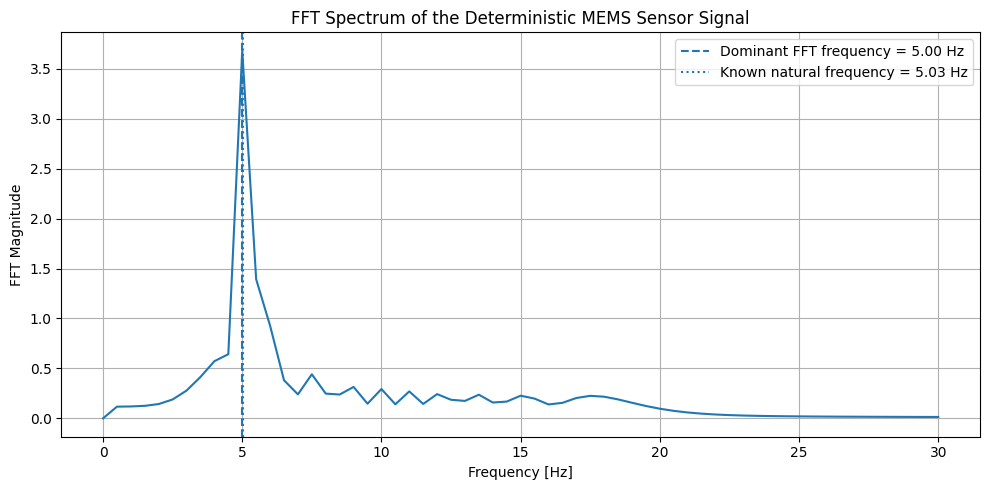

In [9]:
# PLOT THE FFT MAGNITUDE SPECTRUM


# Restrict the displayed frequency range to the dynamically
# relevant low-frequency region.
fft_plot_mask = (
    fft_frequencies <= 30.0
)


plt.figure(figsize=(10, 5))

plt.plot(
    fft_frequencies[fft_plot_mask],
    fft_magnitudes[fft_plot_mask],
)


# Mark the dominant frequency identified numerically.
plt.axvline(
    fft_dominant_frequency,
    linestyle="--",
    label=(
        f"Dominant FFT frequency = "
        f"{fft_dominant_frequency:.2f} Hz"
    ),
)


# Mark the known natural frequency from the deterministic model.
known_natural_frequency = 5.032921

plt.axvline(
    known_natural_frequency,
    linestyle=":",
    label=(
        f"Known natural frequency = "
        f"{known_natural_frequency:.2f} Hz"
    ),
)


plt.xlabel("Frequency [Hz]")
plt.ylabel("FFT Magnitude")
plt.title("FFT Spectrum of the Deterministic MEMS Sensor Signal")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [10]:
# CALCULATE THE POWER SPECTRAL DENSITY

# Estimate the Power Spectral Density (PSD) of the centered
# acceleration signal using Welch's method.
#
# Welch's method divides the signal into shorter overlapping
# segments, calculates a spectrum for each segment, and then
# averages the spectra.
psd_frequencies, psd_values = (
    calculate_power_spectral_density(
        signal_values=centered_signal,
        sampling_frequency=sampling_frequency,
        segment_length=2048,
    )
)


# Calculate the frequency spacing of the PSD estimate.
psd_frequency_resolution = (
    psd_frequencies[1]
    - psd_frequencies[0]
)


# Find the dominant frequency in the PSD while ignoring
# frequencies close to 0 Hz.
psd_dominant_frequency, psd_dominant_value = (
    find_dominant_frequency(
        frequencies=psd_frequencies,
        spectral_values=psd_values,
        minimum_frequency=0.5,
    )
)


print(
    f"PSD frequency spacing:     "
    f"{psd_frequency_resolution:.6f} Hz"
)

print(
    f"Dominant PSD frequency:    "
    f"{psd_dominant_frequency:.6f} Hz"
)

print(
    f"Dominant PSD value:        "
    f"{psd_dominant_value:.6f}"
)

PSD frequency spacing:     4.882812 Hz
Dominant PSD frequency:    4.882812 Hz
Dominant PSD value:        1.305712


In [11]:
# IMPROVE THE PSD FREQUENCY RESOLUTION


# Increase the Welch segment length.
#
# A longer segment provides finer frequency resolution,
# although fewer segments are available for averaging.
improved_segment_length = 8192


# Recalculate the PSD using the longer segment length.
improved_psd_frequencies, improved_psd_values = (
    calculate_power_spectral_density(
        signal_values=centered_signal,
        sampling_frequency=sampling_frequency,
        segment_length=improved_segment_length,
    )
)


# Calculate the new frequency spacing.
improved_psd_frequency_resolution = (
    improved_psd_frequencies[1]
    - improved_psd_frequencies[0]
)


# Find the dominant frequency again.
improved_psd_dominant_frequency, improved_psd_dominant_value = (
    find_dominant_frequency(
        frequencies=improved_psd_frequencies,
        spectral_values=improved_psd_values,
        minimum_frequency=0.5,
    )
)


print(
    f"Improved PSD frequency spacing:  "
    f"{improved_psd_frequency_resolution:.6f} Hz"
)

print(
    f"Dominant improved PSD frequency: "
    f"{improved_psd_dominant_frequency:.6f} Hz"
)

print(
    f"Dominant improved PSD value:     "
    f"{improved_psd_dominant_value:.6f}"
)

Improved PSD frequency spacing:  1.220703 Hz
Dominant improved PSD frequency: 4.882812 Hz
Dominant improved PSD value:     4.657034


### PSD Resolution Consideration

Using a Welch segment length of $2048$ samples resulted in a frequency spacing of approximately

$$
4.88\ \text{Hz},
$$

which was too coarse to resolve the characteristic frequency near $5.03$ Hz accurately.

The dominant PSD component therefore appeared at the nearest available frequency bin,

$$
4.882812\ \text{Hz}.
$$

To improve the frequency resolution, the Welch segment length was increased. This illustrates the trade-off between spectral resolution and spectral averaging in PSD estimation.

After increasing the Welch segment length to $8192$ samples, the frequency spacing improved to approximately

$$
1.220703\ \text{Hz}.
$$

The dominant PSD component remained at

$$
4.882812\ \text{Hz}.
$$

This frequency bin is the closest available PSD frequency to the known natural frequency of

$$
5.032921\ \text{Hz}.
$$

The result therefore remains physically consistent. However, the FFT provides finer frequency localization for the present short deterministic record, while Welch's PSD remains useful as a more averaged spectral estimate that will become particularly valuable when noisy sensor signals are analysed.

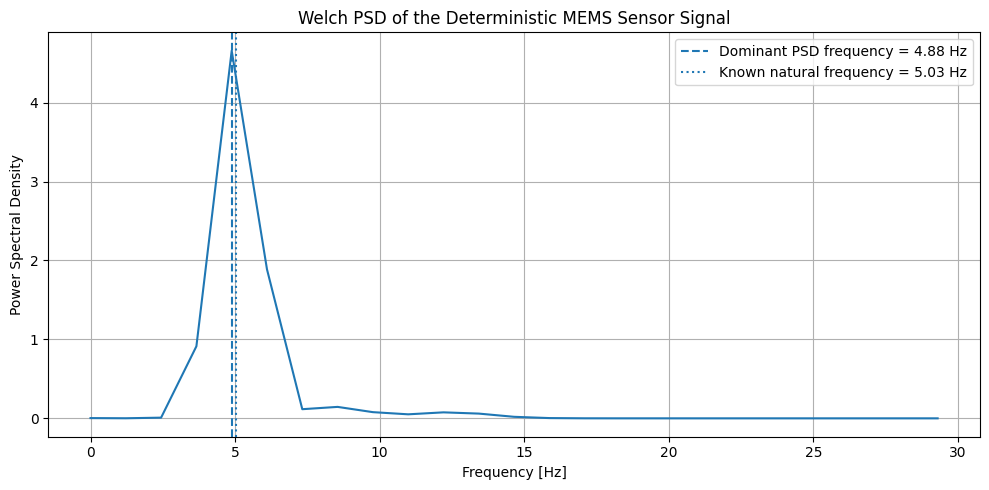

In [12]:
# PLOT THE IMPROVED POWER SPECTRAL DENSITY

# Restrict the displayed frequency range to the
# dynamically relevant region.
psd_plot_mask = (
    improved_psd_frequencies <= 30.0
)


plt.figure(figsize=(10, 5))

plt.plot(
    improved_psd_frequencies[psd_plot_mask],
    improved_psd_values[psd_plot_mask],
)


# Mark the dominant PSD frequency.
plt.axvline(
    improved_psd_dominant_frequency,
    linestyle="--",
    label=(
        f"Dominant PSD frequency = "
        f"{improved_psd_dominant_frequency:.2f} Hz"
    ),
)


# Mark the known natural frequency.
plt.axvline(
    known_natural_frequency,
    linestyle=":",
    label=(
        f"Known natural frequency = "
        f"{known_natural_frequency:.2f} Hz"
    ),
)


plt.xlabel("Frequency [Hz]")
plt.ylabel("Power Spectral Density")
plt.title(
    "Welch PSD of the Deterministic MEMS Sensor Signal"
)

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

In [15]:
# COMPARE PHYSICAL, FFT, AND PSD FREQUENCY ESTIMATES

frequency_comparison = pd.DataFrame(
    {
        "method": [
            "Known physical model",
            "FFT",
            "Welch PSD",
        ],

        "frequency_hz": [
            known_natural_frequency,
            fft_dominant_frequency,
            improved_psd_dominant_frequency,
        ],
    }
)


# Calculate the absolute error relative to the
# known physical natural frequency.
frequency_comparison["absolute_error_hz"] = np.abs(
    frequency_comparison["frequency_hz"]
    - known_natural_frequency
)


frequency_comparison

,method,frequency_hz,absolute_error_hz
0,Known physical model,5.032921,0.000000
1,FFT,4.999750,0.033171
2,Welch PSD,4.882812,0.150108


### Comparison of Frequency Estimates

The dominant frequency obtained from the FFT was

$$
f_{\mathrm{FFT}} = 4.999750\ \text{Hz},
$$

corresponding to an absolute error of

$$
0.033171\ \text{Hz}
$$

relative to the known physical natural frequency.

The dominant Welch PSD frequency was

$$
f_{\mathrm{PSD}} = 4.882812\ \text{Hz},
$$

with an absolute error of

$$
0.150108\ \text{Hz}.
$$

For the present short and noise-free deterministic signal, the FFT therefore provides the more accurate frequency estimate. This is primarily due to its finer frequency resolution.

Welch's PSD provides a smoother and more averaged spectral representation, and its robustness is expected to become more useful when noisy or uncertain sensor measurements are analysed.

In [18]:
# CALCULATE RELATIVE FREQUENCY ERRORS

# Calculate the relative error of each frequency estimate
# with respect to the known physical natural frequency.

frequency_comparison["relative_error_percent"] = (
    frequency_comparison["absolute_error_hz"]
    / known_natural_frequency
    * 100.0
)


frequency_comparison

,method,frequency_hz,absolute_error_hz,relative_error_percent
0,Known physical model,5.032921,0.000000,0.000000
1,FFT,4.999750,0.033171,0.659080
2,Welch PSD,4.882812,0.150108,2.982532


The corresponding relative frequency errors are approximately

$$
0.659\%
$$

for the FFT estimate and

$$
2.983\%
$$

for the Welch PSD estimate.

The FFT therefore provides the more accurate frequency estimate for the present deterministic signal, while the PSD retains value as a smoother spectral estimator for later noisy-signal analyses.

In [20]:
# CREATE A BASELINE SIGNAL-FEATURE TABLE


# Build one compact row containing important time-domain
# and frequency-domain characteristics of the baseline signal.

baseline_signal_features = pd.DataFrame(
    {
        "signal_mean": [
            measured_signal_mean
        ],

        "signal_standard_deviation": [
            measured_signal_std
        ],

        "signal_rms": [
            measured_signal_rms
        ],

        "signal_minimum": [
            measured_signal_min
        ],

        "signal_maximum": [
            measured_signal_max
        ],

        "fft_dominant_frequency": [
            fft_dominant_frequency
        ],

        "fft_dominant_magnitude": [
            fft_dominant_magnitude
        ],

        "psd_dominant_frequency": [
            improved_psd_dominant_frequency
        ],

        "psd_dominant_value": [
            improved_psd_dominant_value
        ],

        "fft_frequency_error_hz": [
            abs(
                fft_dominant_frequency
                - known_natural_frequency
            )
        ],

        "psd_frequency_error_hz": [
            abs(
                improved_psd_dominant_frequency
                - known_natural_frequency
            )
        ],
    }
)


baseline_signal_features

,signal_mean,signal_standard_deviation,signal_rms,signal_minimum,signal_maximum,fft_dominant_frequency,fft_dominant_magnitude,psd_dominant_frequency,psd_dominant_value,fft_frequency_error_hz,psd_frequency_error_hz
0,0.058213,3.074621,3.075172,-6.122566,6.375896,4.99975,3.681979,4.882812,4.657034,0.033171,0.150108


In [21]:
# CREATE AND SAVE THE INTERIM SIGNAL DATASET


# Create a new DataFrame containing the original measured signal
# together with the mean-centered version used for spectral analysis.
#
# This is considered "interim" data because it has been transformed
# from the raw sensor signal but has not yet been reduced to final
# signal features.

baseline_interim_data = pd.DataFrame(
    {
        "time": time_values,
        "excitation": baseline_data["excitation"].to_numpy(),
        "measured_signal": measured_signal,
        "centered_signal": centered_signal,
    }
)


# Create the interim-data directory.
interim_data_directory = data_path(
    "interim"
)

ensure_directory(
    interim_data_directory
)


# Define the output file.
baseline_interim_path = (
    interim_data_directory
    / "deterministic_baseline_centered.csv"
)


# Save the transformed signal.
baseline_interim_data.to_csv(
    baseline_interim_path,
    index=False,
)


print("Interim signal dataset saved to:")
print(baseline_interim_path)

print()
print(
    f"Interim dataset shape: "
    f"{baseline_interim_data.shape}"
)

Interim signal dataset saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\data\interim\deterministic_baseline_centered.csv

Interim dataset shape: (20001, 4)


In [22]:
# SAVE THE PROCESSED BASELINE SIGNAL FEATURES


# Create the processed-data directory.
processed_data_directory = data_path(
    "processed"
)

ensure_directory(
    processed_data_directory
)


# Define the output file for the final compact
# signal-feature representation.
baseline_features_path = (
    processed_data_directory
    / "deterministic_baseline_signal_features.csv"
)


# Save the feature table.
baseline_signal_features.to_csv(
    baseline_features_path,
    index=False,
)


print("Processed signal features saved to:")
print(baseline_features_path)

print()
print(
    f"Processed feature table shape: "
    f"{baseline_signal_features.shape}"
)

Processed signal features saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\data\processed\deterministic_baseline_signal_features.csv

Processed feature table shape: (1, 11)


In [26]:
# SAVE THE FREQUENCY-ESTIMATION COMPARISON


# Create the signal-processing results directory.
signal_processing_results_directory = results_path(
    "signal_processing"
)

ensure_directory(
    signal_processing_results_directory
)


# Define the output file.
frequency_comparison_path = (
    signal_processing_results_directory
    / "frequency_estimation_comparison.csv"
)


# Save the comparison between:
#
# - known physical natural frequency,
# - FFT estimate,
# - Welch PSD estimate.
frequency_comparison.to_csv(
    frequency_comparison_path,
    index=False,
)


print("Frequency comparison saved to:")
print(frequency_comparison_path)

Frequency comparison saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\results\signal_processing\frequency_estimation_comparison.csv


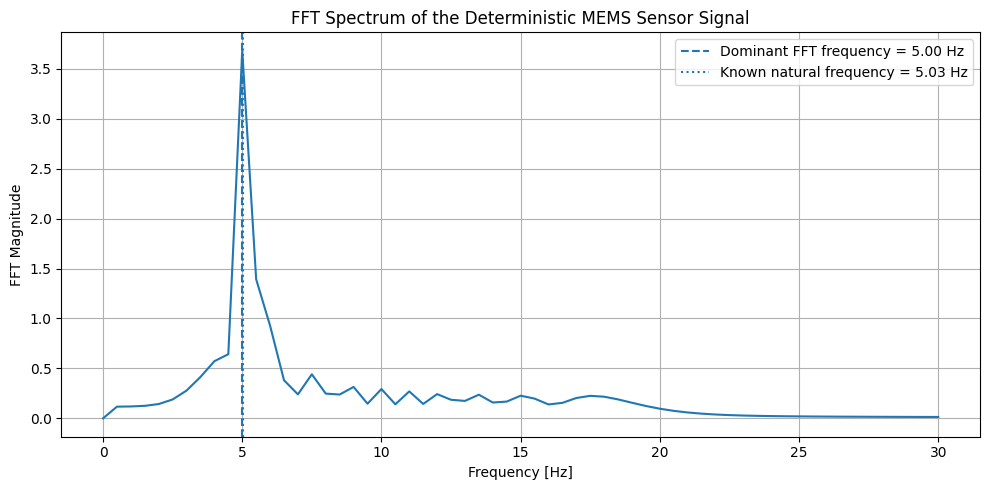

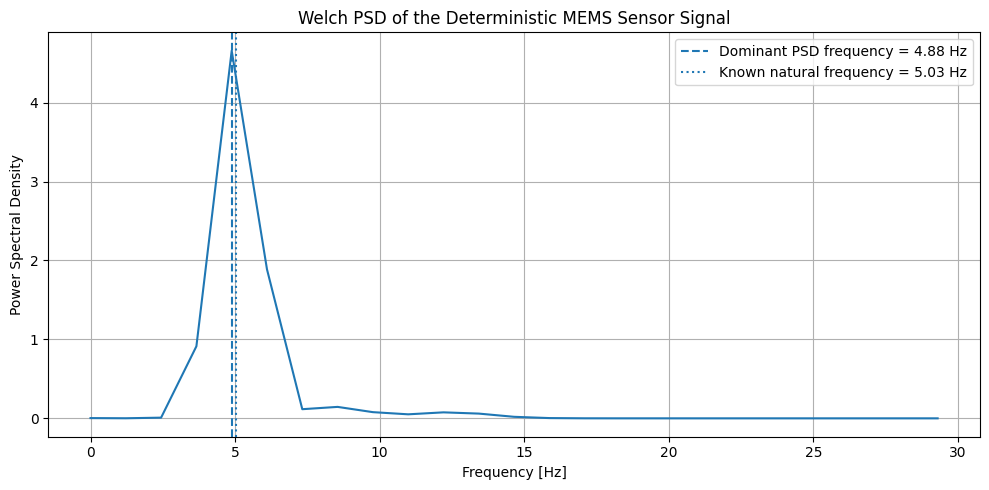

FFT figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\signal_processing\deterministic_baseline_fft_spectrum.png

PSD figure saved to:
D:\Uni\Mechanical Enginnering Masters\Extra\Data Analysis and Info Engineering\Part II Information Engineering\monte_carlo_mems_sciml\figures\signal_processing\deterministic_baseline_welch_psd.png


In [27]:
# SAVE THE FFT AND PSD FIGURES

# Create the signal-processing figure directory.
signal_processing_figure_directory = figures_path(
    "signal_processing"
)

ensure_directory(
    signal_processing_figure_directory
)



# SAVE FFT FIGURE
plt.figure(figsize=(10, 5))

plt.plot(
    fft_frequencies[fft_plot_mask],
    fft_magnitudes[fft_plot_mask],
)

plt.axvline(
    fft_dominant_frequency,
    linestyle="--",
    label=(
        f"Dominant FFT frequency = "
        f"{fft_dominant_frequency:.2f} Hz"
    ),
)

plt.axvline(
    known_natural_frequency,
    linestyle=":",
    label=(
        f"Known natural frequency = "
        f"{known_natural_frequency:.2f} Hz"
    ),
)

plt.xlabel("Frequency [Hz]")
plt.ylabel("FFT Magnitude")
plt.title("FFT Spectrum of the Deterministic MEMS Sensor Signal")

plt.legend()
plt.grid(True)
plt.tight_layout()

fft_figure_path = (
    signal_processing_figure_directory
    / "deterministic_baseline_fft_spectrum.png"
)

plt.savefig(
    fft_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()



# SAVE PSD FIGURE
plt.figure(figsize=(10, 5))

plt.plot(
    improved_psd_frequencies[psd_plot_mask],
    improved_psd_values[psd_plot_mask],
)

plt.axvline(
    improved_psd_dominant_frequency,
    linestyle="--",
    label=(
        f"Dominant PSD frequency = "
        f"{improved_psd_dominant_frequency:.2f} Hz"
    ),
)

plt.axvline(
    known_natural_frequency,
    linestyle=":",
    label=(
        f"Known natural frequency = "
        f"{known_natural_frequency:.2f} Hz"
    ),
)

plt.xlabel("Frequency [Hz]")
plt.ylabel("Power Spectral Density")
plt.title("Welch PSD of the Deterministic MEMS Sensor Signal")

plt.legend()
plt.grid(True)
plt.tight_layout()

psd_figure_path = (
    signal_processing_figure_directory
    / "deterministic_baseline_welch_psd.png"
)

plt.savefig(
    psd_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print("FFT figure saved to:")
print(fft_figure_path)

print()

print("PSD figure saved to:")
print(psd_figure_path)

In [28]:
# FINAL OUTPUT VALIDATION FOR NOTEBOOK 03

notebook_03_outputs = {
    "interim_signal": baseline_interim_path,
    "processed_features": baseline_features_path,
    "frequency_comparison": frequency_comparison_path,
    "fft_figure": fft_figure_path,
    "psd_figure": psd_figure_path,
}


for output_name, output_path in notebook_03_outputs.items():

    print(
        f"{output_name:25s} "
        f"{output_path.exists()}"
    )

interim_signal            True
processed_features        True
frequency_comparison      True
fft_figure                True
psd_figure                True


# Notebook 03 Summary

This notebook analysed the deterministic MEMS sensor response in both the time and frequency domains.

The acceleration signal had an RMS value of approximately

$$
3.0752.
$$

Frequency-domain analysis showed a strong spectral concentration near the known natural frequency of the physical model.

The FFT identified a dominant frequency of

$$
4.999750\ \text{Hz},
$$

compared with the known physical natural frequency of

$$
5.032921\ \text{Hz}.
$$

This corresponds to an absolute error of approximately

$$
0.033171\ \text{Hz}
$$

and a relative error of approximately

$$
0.659\%.
$$

Welch's power spectral density estimate identified the dominant frequency at

$$
4.882812\ \text{Hz},
$$

with an absolute error of approximately

$$
0.150108\ \text{Hz}
$$

and a relative error of approximately

$$
2.983\%.
$$

For the present short and noise-free deterministic signal, the FFT therefore provided finer frequency localisation than the Welch PSD. Welch's method nevertheless provides a smoother spectral estimate and is expected to become particularly useful when noisy and uncertain sensor signals are analysed.

The notebook also established the signal-processing data pipeline:

$$
\text{raw signal}
\rightarrow
\text{interim transformed signal}
\rightarrow
\text{processed signal features}.
$$

The transformed mean-centered time series was stored in the interim-data directory, while a compact set of time-domain and frequency-domain features was stored in the processed-data directory.

These extracted signal characteristics provide the foundation for the subsequent system-identification and equation-discovery analyses.